# Import Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# create dataset

In [3]:
data = {
    'Feature1': [1, 1.5, 2, 8, 8.5, 9, 1.2, 8.2, 2.2],
    'Feature2': [1, 2, 1.5, 8, 9, 8.5, 1.8, 7.5, 2.5]
}

df = pd.DataFrame(data)

print("Original Dataset:")
display(df)

Original Dataset:


,Feature1,Feature2
0,1.0,1.0
1,1.5,2.0
2,2.0,1.5
3,8.0,8.0
4,8.5,9.0
5,9.0,8.5
6,1.2,1.8
7,8.2,7.5
8,2.2,2.5


# Feature Scaling

In [4]:
X = df[['Feature1', 'Feature2']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Features:")
print(X_scaled)

Scaled Features:
[[-1.056783   -1.11528503]
 [-0.91090805 -0.8092617 ]
 [-0.76503309 -0.96227337]
 [ 0.98546636  1.02687829]
 [ 1.13134131  1.33290162]
 [ 1.27721627  1.17988996]
 [-0.99843302 -0.87046637]
 [ 1.04381634  0.87386663]
 [-0.70668311 -0.65625003]]


# Elbow Method

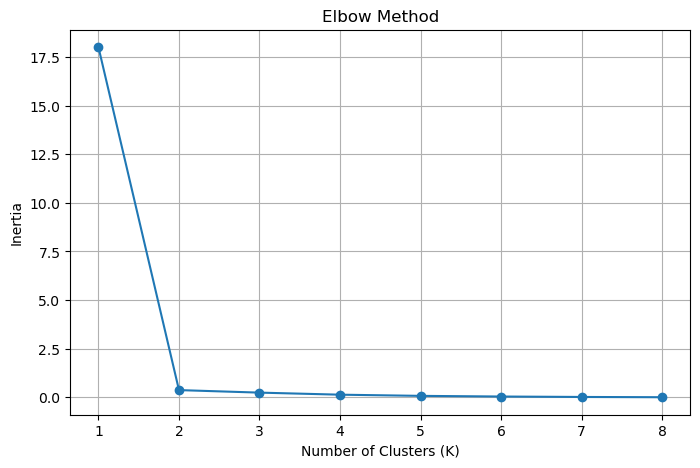

In [5]:

inertia = []

for k in range(1, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 9), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 9))
plt.grid(True)
plt.show()

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

# Apply K-Means clustering

In [6]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df['Cluster'] = clusters

print("Clustered Dataset:")
display(df)

Clustered Dataset:


,Feature1,Feature2,Cluster
0,1.0,1.0,1
1,1.5,2.0,1
2,2.0,1.5,1
3,8.0,8.0,0
4,8.5,9.0,2
5,9.0,8.5,2
6,1.2,1.8,1
7,8.2,7.5,0
8,2.2,2.5,1


# Visualize clusters and centroids

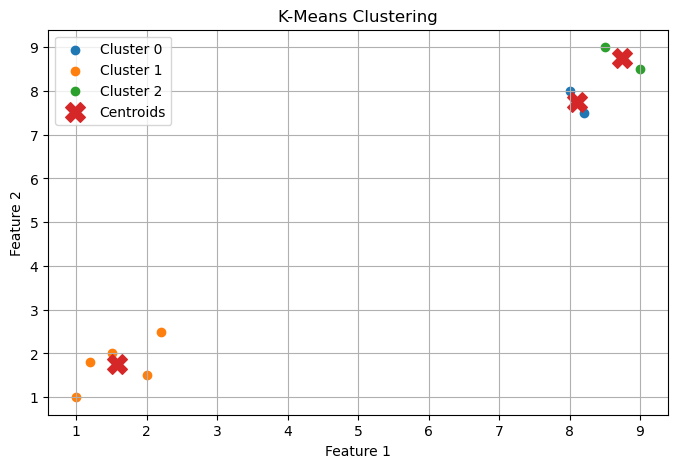

In [7]:
plt.figure(figsize=(8, 5))

for cluster in sorted(df['Cluster'].unique()):
    points = df[df['Cluster'] == cluster]

    plt.scatter(
        points['Feature1'],
        points['Feature2'],
        label=f'Cluster {cluster}'
    )

centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()
plt.grid(True)
plt.show()

# Calculate Silhouette Score

In [8]:
score = silhouette_score(X_scaled, clusters)

print("Silhouette Score:", score)

Silhouette Score: 0.7154802417189606


# Display cluster quality and centroids

In [9]:
print("Number of Clusters:", kmeans.n_clusters)

print("\nNumber of Data Points in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

print("\nCluster Centroids:")
print(centroids)

print("\nInertia:", kmeans.inertia_)

Number of Clusters: 3

Number of Data Points in Each Cluster:
Cluster
0    2
1    5
2    2
Name: count, dtype: int64

Cluster Centroids:
[[8.1  7.75]
 [1.58 1.76]
 [8.75 8.75]]

Inertia: 0.24220850533386476
